In [2]:
import sys

sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tqdm

from src.config import load_config
from src.data import load_complete
from src.data.preprocessing import preprocess_from_config
from src.figures import plot_archetypes_loadings_grid

sns.set_style("whitegrid")
config = load_config()

In [3]:
SEED = config["unmixing"].getint("seed")  # pipeline (VCA/MVSA init) seed
PERM_SEED = 1000  # separate stream for the precinct shuffles
P = config["unmixing"].getint("n_archetypes") or None
PS = [
    2,
    3,
    4,
    5,
    6,
]  # sweep; anchors: config value (6) and nb08's min-pairwise-distance choice (4)
n_trials = 50

df = load_complete(config)

# Canonical preprocessing: reference precinct order shared by all runs
pre_ref = preprocess_from_config(df, config)
Y_ref = pre_ref.Y
L, N = Y_ref.shape
candidate_labels = pre_ref.candidate_labels
ref_ids = pd.Index(pre_ref.params["precinct_ids"])

candidates: 66 -> 66 (25th pct >= 1.0)
precincts:  92,488 -> 92,487 (total votes >= 1.0)
Y: 66 candidates x 92,487 precincts (valid_ballots normalization)


In [4]:
Y_ref.shape

(66, 92487)

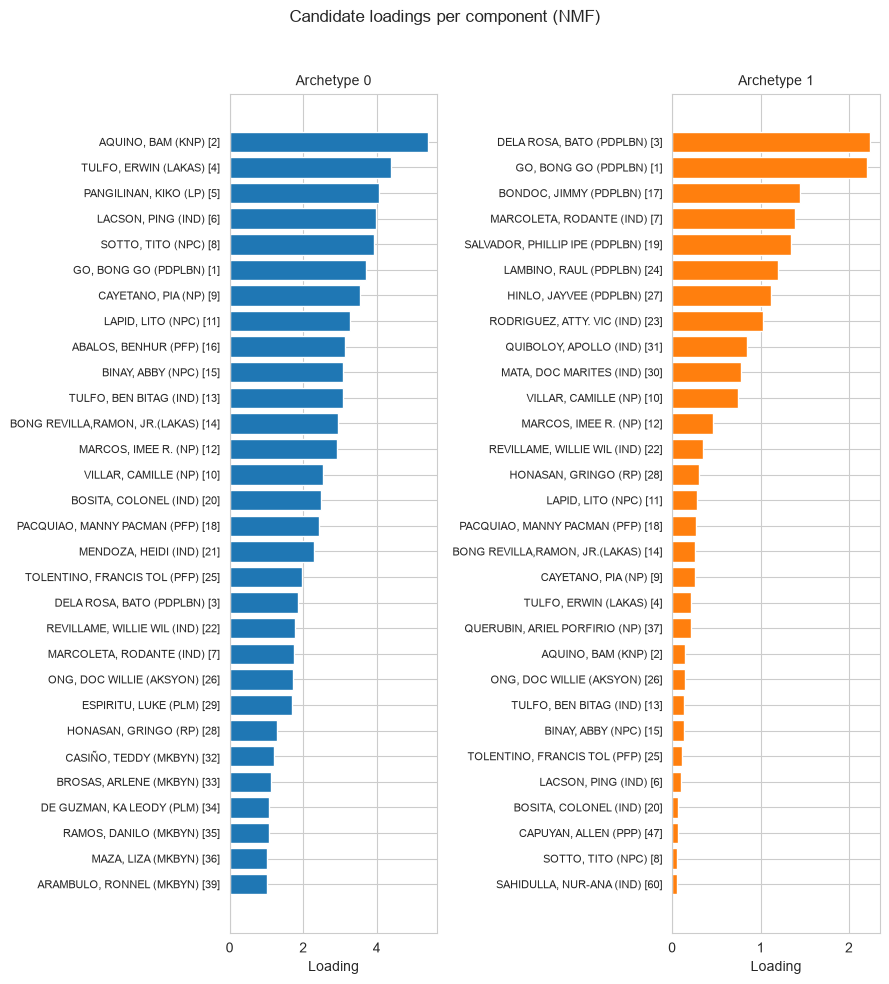

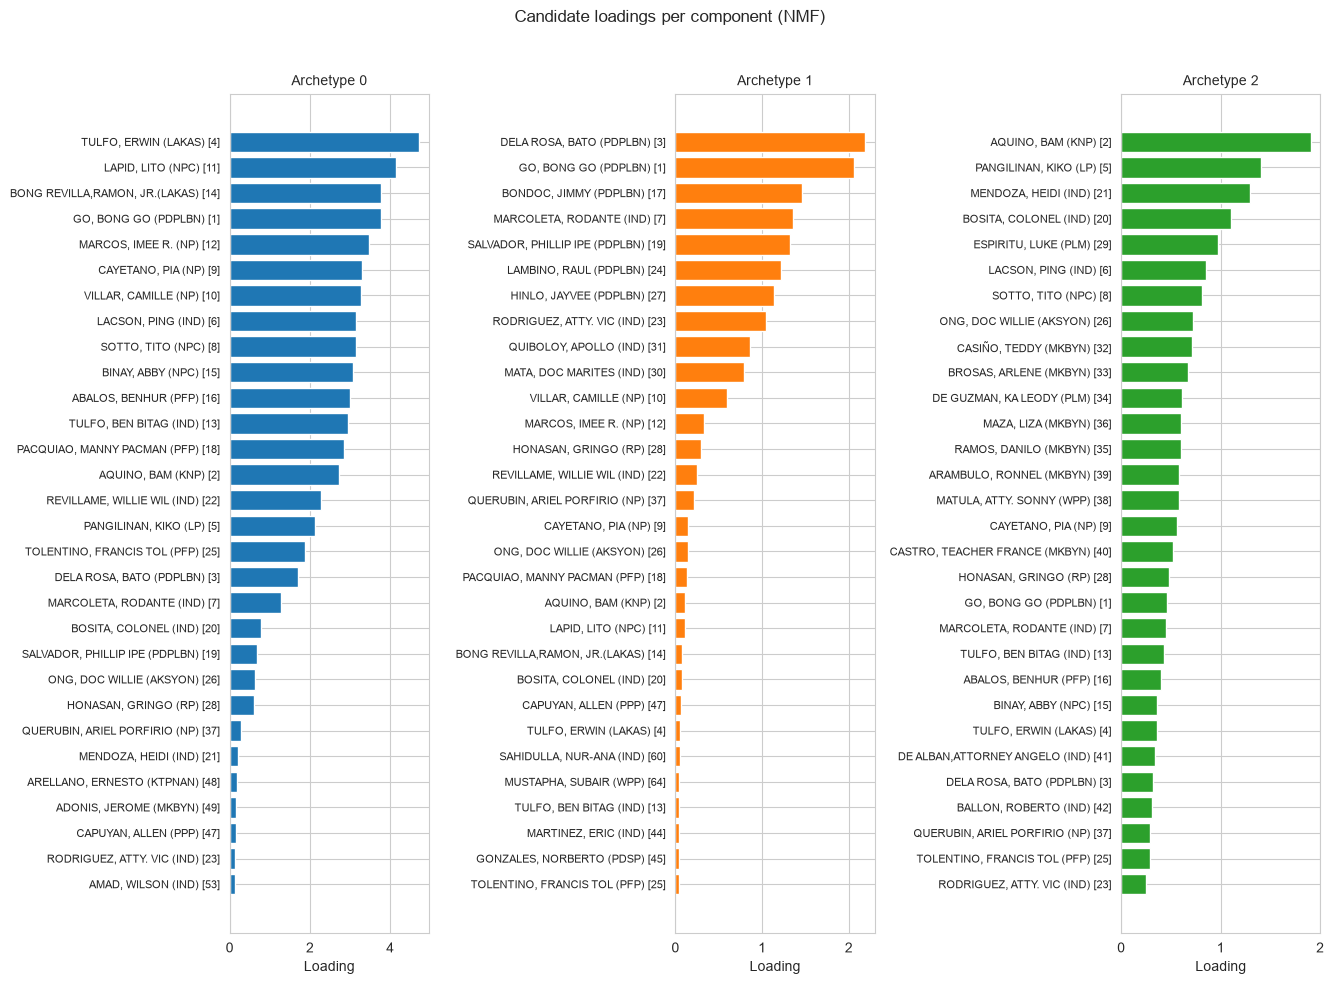

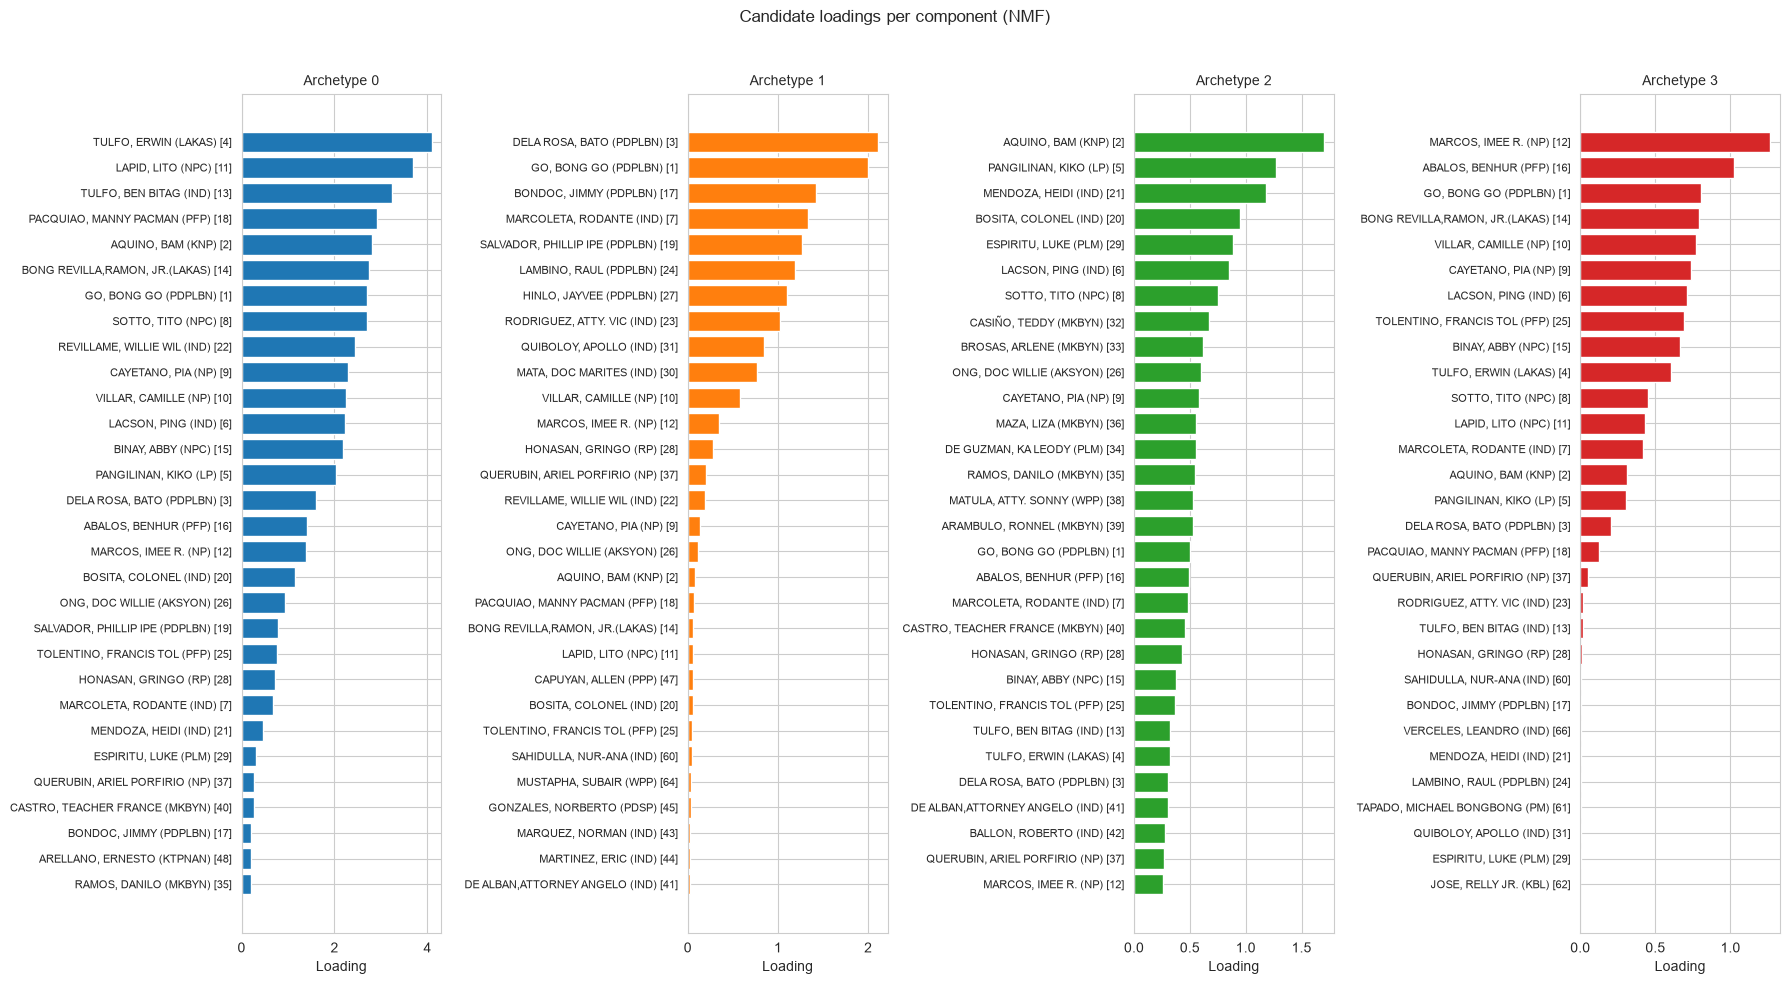

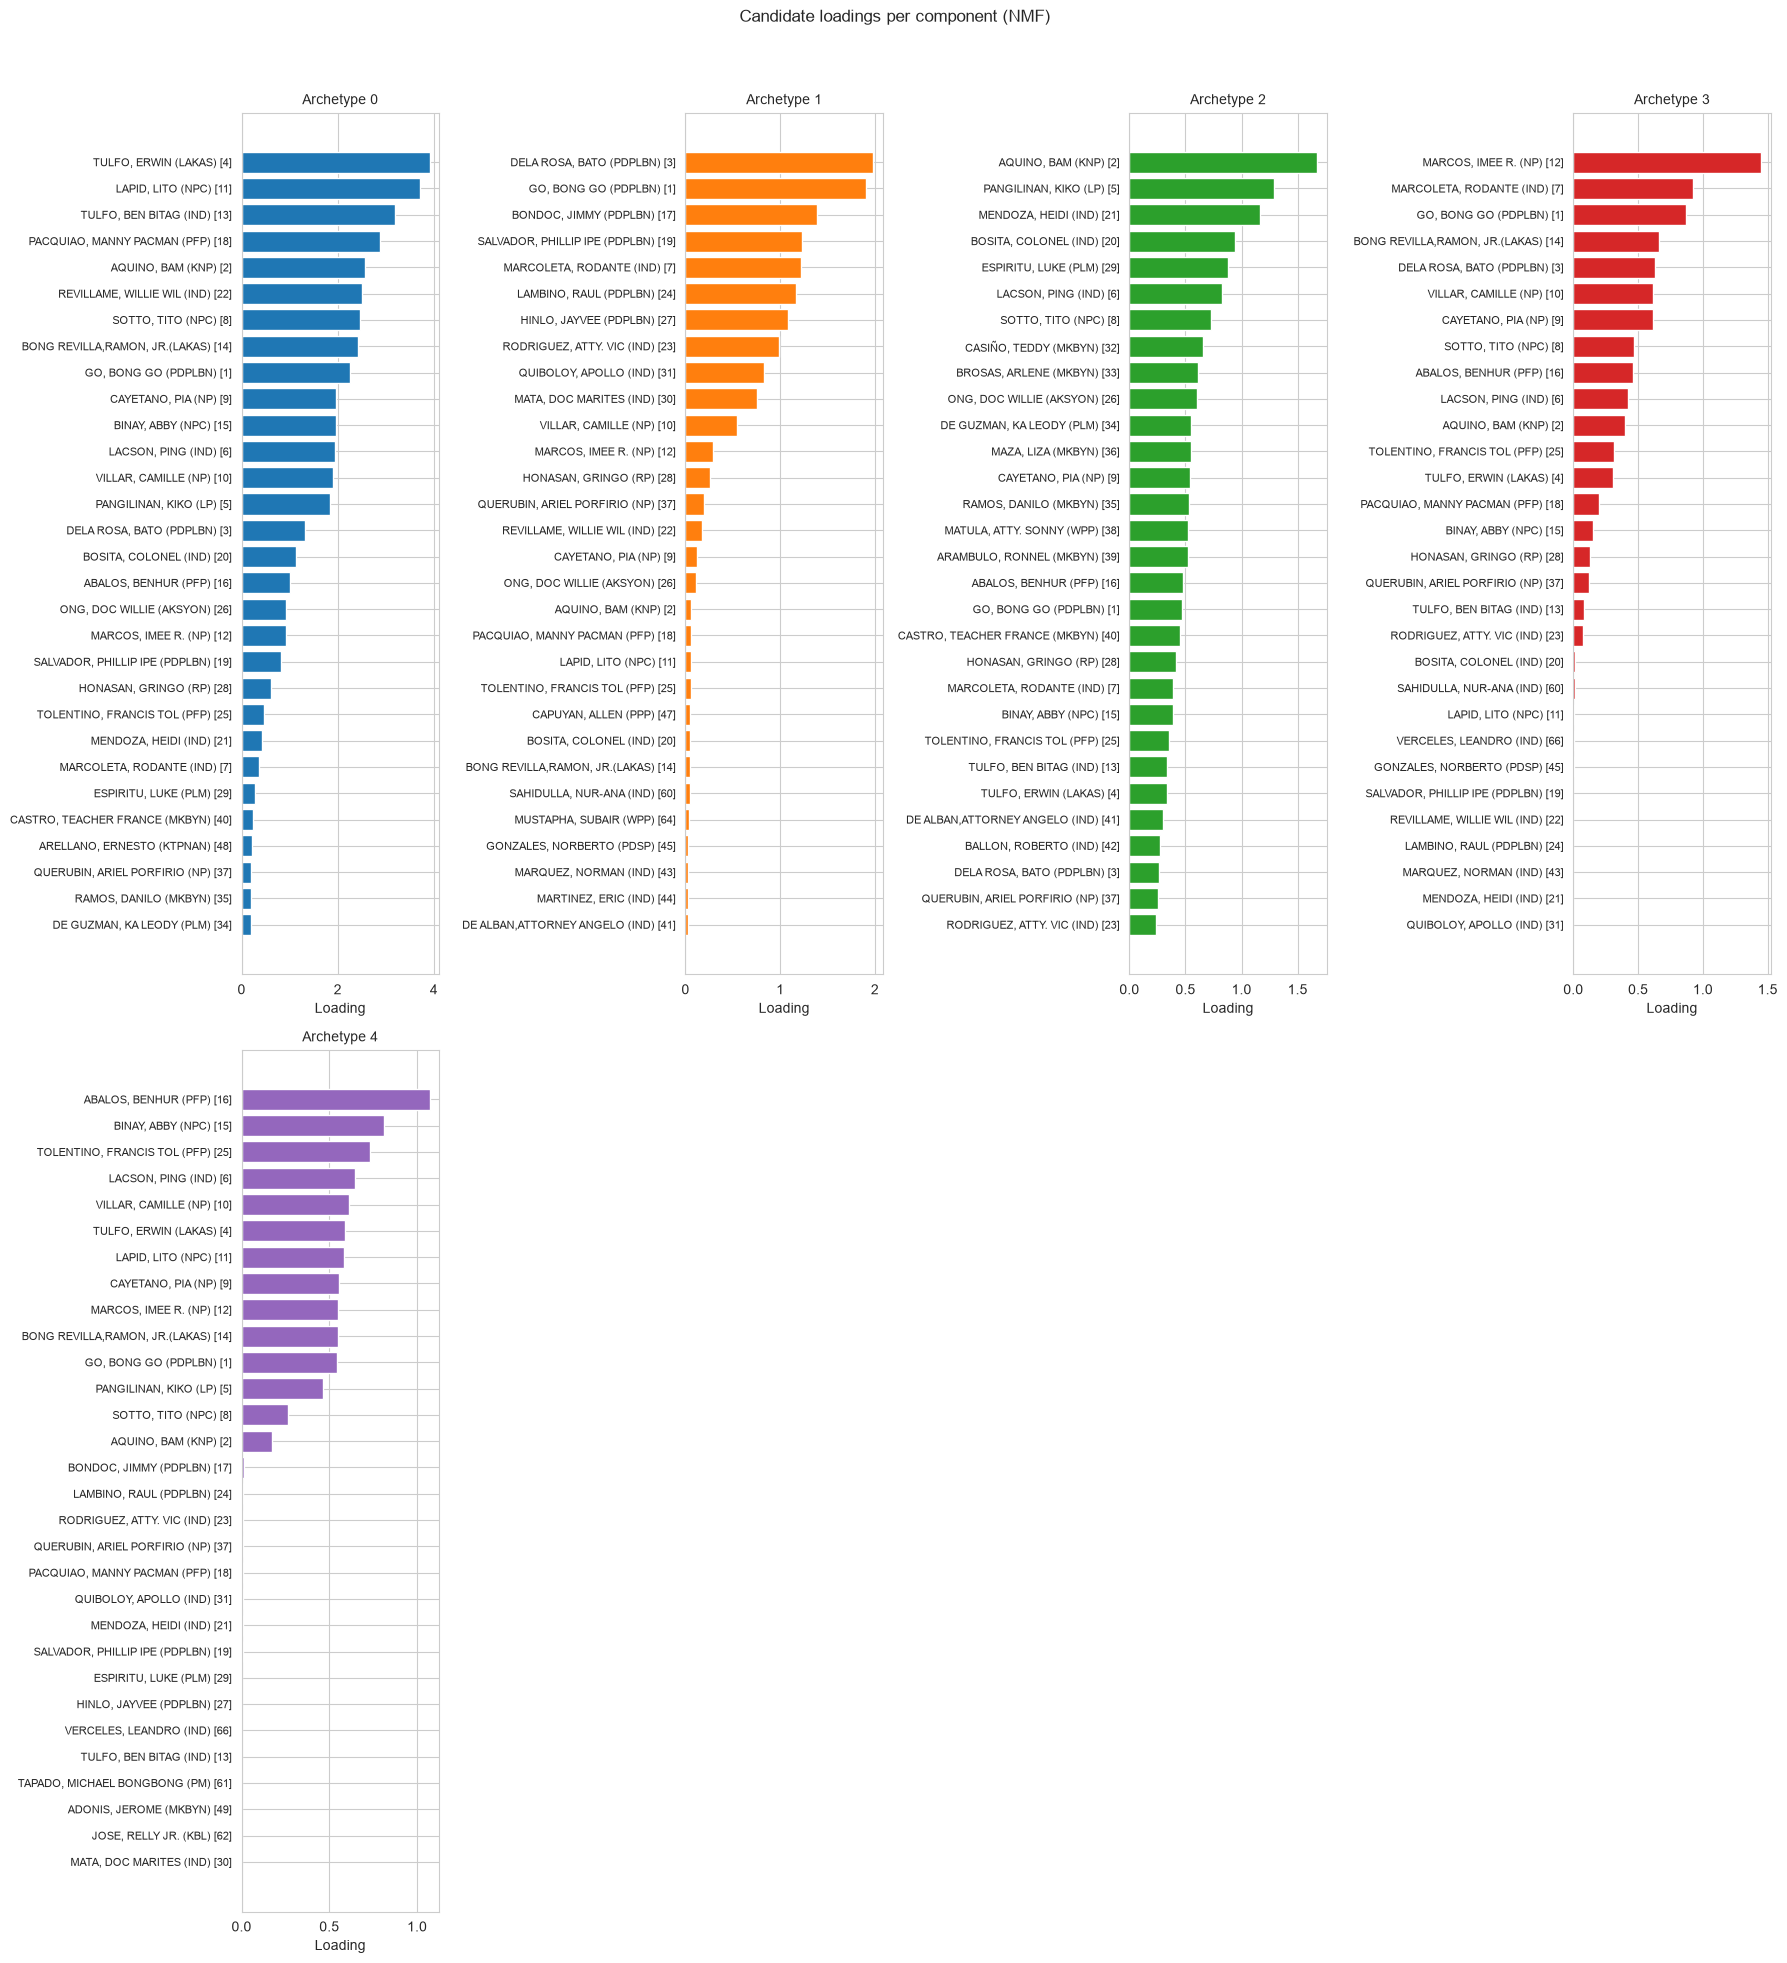

In [5]:
from sklearn.decomposition import NMF

for i in range(2, 6):
    model = NMF(n_components=i, init='nndsvda', beta_loss='kullback-leibler', solver='mu', max_iter=10000)
    W = model.fit_transform(Y_ref)

    plot_archetypes_loadings_grid(
        W, candidate_labels, top_n=30, suptitle="Candidate loadings per component (NMF)"
    )

## NMF with a deterministic NNDSVD initialization

The NMF sweep (`run_sweep.py --method nmf`) uses a **random** initialization, so each
trial lands somewhere different and the dashboard shows loadings as mean ± 1 SD over
50 trials. **NNDSVD** (nonnegative double SVD) instead builds the starting W and H from
the data's SVD, so it has a single, seed-independent result per p.
`scripts/run_nndsvd.py` computes it for every year and p and aligns its archetypes
to the sweep's consensus loadings; the dashboard overlays it on the NMF loadings bars.

**The catch.** Our NMF uses the Kullback–Leibler loss (notebook 10). In scikit-learn
only the multiplicative-update solver (`mu`) supports losses other than Frobenius, and
a multiplicative update scales each entry by a non-negative factor,

$$W_{ik} \leftarrow W_{ik}\,\frac{\big[(Y \oslash WH)\,H^\top\big]_{ik}}{\sum_j H_{kj}},$$

so an entry that **starts** at exactly 0 **stays** 0. NNDSVD's starting point has many
exact zeros (it keeps the positive or the negative part of each singular vector),
so those loadings are fixed by the initialization, not fitted to the data.
sklearn warns about exactly this (see notebook 10).

This notebook documents the effect for the paper:

1. **Baked runs**: how NNDSVD compares with the random-init sweep in every year
   (reads the `run_nndsvd.py` outputs; no fitting).
2. **Mechanism**: the zero pattern of the NNDSVD init survives `mu` unchanged, but not
   an additive solver.
3. **Alternatives** on one year: `nndsvda` / `nndsvdar` (zeros filled before `mu`
   starts) and `nndsvd` with the coordinate-descent solver (which forces the Frobenius
   loss).

In [ ]:
import pickle
import sys
import warnings
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import NMF
from sklearn.decomposition._nmf import _initialize_nmf  # private: the init NMF itself calls

from src.config import REPO_ROOT, load_config
from src.data import load_complete
from src.data.loading import load_sweep
from src.data.preprocessing import preprocess_from_config
from src.unmixing import extract_endmembers, match_to_reference, method_params, sunsal_mod
from src.unmixing.methods import params_tag

sns.set_style("whitegrid")

YEARS = ["2013", "2016", "2019", "2022", "2025"]
CONFIGS = {y: load_config(REPO_ROOT / "configs" / f"config_{y}.ini") for y in YEARS}

## 1. Baked runs: NNDSVD vs the random-init sweep

One row per (year, p): the NNDSVD run's reconstruction RMSE (after SUNSAL, like every
pipeline run) against the 50 random-init trials, how many of those trials it beats,
and the fraction of its loadings that are exactly 0. Refresh with
`python scripts/run_nndsvd.py --config configs/config_<year>.ini`.

In [ ]:
rows, cos_rows = [], []
for y in YEARS:
    for p, e in load_sweep(CONFIGS[y], method="nmf").items():
        if "nndsvd_meta" not in e:
            continue
        n = e["nndsvd_meta"]
        rmse_trials = np.array(e["meta"]["rmse_trials"])
        rows.append(
            {
                "year": y,
                "p": p,
                "init": n["init"],
                "rmse": n["rmse"],
                "rmse_random_mean": rmse_trials.mean(),
                "rmse_random_std": rmse_trials.std(ddof=1),
                "rmse_random_min": rmse_trials.min(),
                "trials_beaten": int((rmse_trials > n["rmse"]).sum()),
                "n_trials": len(rmse_trials),
                "zero_fraction": n["zero_fraction"],
            }
        )
        cos_rows += [
            {"year": y, "p": p, "k": k, "cosine": c}
            for k, c in enumerate(n["matched_cosine_to_sweep_mean"])
        ]
baked = pd.DataFrame(rows)
baked["rel_gap"] = baked["rmse"] / baked["rmse_random_mean"] - 1
cos_df = pd.DataFrame(cos_rows)
baked.round(4)

,year,p,init,rmse,rmse_random_mean,rmse_random_std,rmse_random_min,trials_beaten,n_trials,zero_fraction,rel_gap
0,2013,2,nndsvd,0.1329,0.1310,0.0013,0.1303,2,50,0.2258,0.0143
1,2013,3,nndsvd,0.1254,0.1219,0.0005,0.1209,0,50,0.2796,0.0285
2,2013,4,nndsvd,0.1178,0.1131,0.0003,0.1125,0,50,0.2903,0.0418
3,2013,5,nndsvd,0.1144,0.1084,0.0006,0.1075,0,50,0.3677,0.0561
4,2013,6,nndsvd,0.1118,0.1050,0.0006,0.1037,0,50,0.3602,0.0654
5,2013,7,nndsvd,0.1089,0.1017,0.0004,0.1006,0,50,0.4147,0.0708
6,2016,2,nndsvd,0.1145,0.1134,0.0009,0.1119,2,50,0.1800,0.0103
7,2016,3,nndsvd,0.1099,0.1069,0.0004,0.1052,0,50,0.3133,0.0280
8,2016,4,nndsvd,0.1033,0.0997,0.0005,0.0991,0,50,0.3250,0.0361
9,2016,5,nndsvd,0.1003,0.0956,0.0004,0.0947,0,50,0.3880,0.0494


In [ ]:
cos = cos_df["cosine"]
print(
    f"{len(baked)} (year, p) runs, init = {sorted(baked['init'].unique())}\n"
    f"zero loadings:           {baked.zero_fraction.min():.1%} – {baked.zero_fraction.max():.1%}\n"
    f"RMSE vs random mean:     +{baked.rel_gap.min():.1%} – +{baked.rel_gap.max():.1%}\n"
    f"random trials beaten:    at most {baked.trials_beaten.max()} of {baked.n_trials.max()}; "
    f"none in {(baked.trials_beaten == 0).sum()} of {len(baked)} runs\n"
    f"matched cosine to sweep: median {cos.median():.2f}, "
    f"{(cos >= 0.9).sum()} of {len(cos)} archetypes >= 0.9, "
    f"{(cos < 0.7).sum()} below 0.7, min {cos.min():.2f}"
)

30 (year, p) runs, init = ['nndsvd']
zero loadings:           18.0% – 45.2%
RMSE vs random mean:     +1.0% – +7.1%
random trials beaten:    at most 2 of 50; none in 27 of 30 runs
matched cosine to sweep: median 0.87, 53 of 135 archetypes >= 0.9, 23 below 0.7, min 0.37


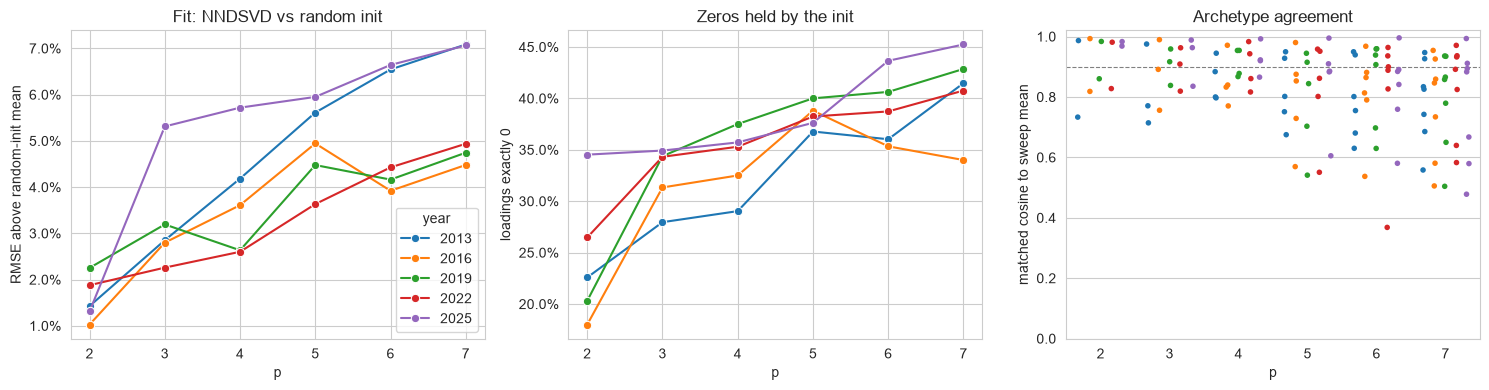

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.lineplot(data=baked, x="p", y="rel_gap", hue="year", marker="o", ax=axes[0])
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0].set(ylabel="RMSE above random-init mean", title="Fit: NNDSVD vs random init")
sns.lineplot(data=baked, x="p", y="zero_fraction", hue="year", marker="o", ax=axes[1], legend=False)
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[1].set(ylabel="loadings exactly 0", title="Zeros held by the init")
sns.stripplot(data=cos_df, x="p", y="cosine", hue="year", dodge=True, size=4, ax=axes[2], legend=False)
axes[2].axhline(0.9, color="grey", lw=0.8, ls="--")
axes[2].set(ylabel="matched cosine to sweep mean", title="Archetype agreement", ylim=(0, 1.02))
plt.tight_layout()

## 2. Mechanism: `mu` cannot move the init's zeros

Fit one year and p from the exact NNDSVD starting point (`init="custom"` with sklearn's
own NNDSVD init) and compare the zero pattern before and after. With `mu` the masks
should be identical; with the additive coordinate-descent solver (`cd`, Frobenius loss
only in sklearn) zeros are free to become non-zero.

In [ ]:
YEAR, P = "2016", 4  # any year / p; 2016 is the quickest

config = CONFIGS[YEAR]
params = method_params(config["unmixing"], "nmf")
pre = preprocess_from_config(load_complete(config), config)
Y = pre.Y
print(f"{YEAR}: Y {Y.shape}, NMF params {params}")

candidates: 50 -> 50 (25th pct >= 1.0)
precincts:  22,986 -> 22,986 (total votes >= 1.0)
Y: 50 candidates x 22,986 precincts (row_max normalization)
2016: Y (50, 22986), NMF params {'init': 'random', 'beta_loss': 'kullback-leibler', 'solver': 'mu', 'max_iter': 1000, 'tol': 0.0001}


In [ ]:
def fit_from_init(Y, p, W0, H0, solver, beta_loss):
    model = NMF(
        n_components=p,
        init="custom",
        solver=solver,
        beta_loss=beta_loss,
        max_iter=params["max_iter"],
        tol=params["tol"],
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # the mu/zeros warning is the point here
        W = model.fit_transform(Y, W=W0.copy(), H=H0.copy())
    return W, model.components_


W0, H0 = _initialize_nmf(Y, P, init="nndsvd")
for solver, loss in [("mu", params["beta_loss"]), ("cd", "frobenius")]:
    W, H = fit_from_init(Y, P, W0, H0, solver, loss)
    for name, A0, A in [("W", W0, W), ("H", H0, H)]:
        z0 = A0 == 0
        print(
            f"{solver:>2} / {loss:<16} {name}: {z0.mean():6.1%} zero at init, "
            f"{(A[z0] == 0).mean():6.1%} of those still exactly 0 after fitting "
            f"({(A == 0).mean():6.1%} zero overall)"
        )

mu / kullback-leibler W:  32.5% zero at init, 100.0% of those still exactly 0 after fitting ( 32.5% zero overall)
mu / kullback-leibler H:  40.4% zero at init, 100.0% of those still exactly 0 after fitting ( 40.4% zero overall)


cd / frobenius        W:  32.5% zero at init,  23.1% of those still exactly 0 after fitting ( 13.5% zero overall)
cd / frobenius        H:  40.4% zero at init,   7.3% of those still exactly 0 after fitting (  4.0% zero overall)


## 3. Alternatives on one year

Each variant is fitted at every p of the sweep, then run through SUNSAL like the pipeline:

| variant | what changes |
|---|---|
| `nndsvd` (mu, KL) | the baked run: zeros held by the init |
| `nndsvda` (mu, KL) | NNDSVD's zeros filled with the data mean $\bar{Y}$ before fitting; still deterministic. The random init starts every entry at $\lvert\mathcal{N}(0,1)\rvert\sqrt{\bar{Y}/p}$, about the same size, so the filled value is a neutral starting point, not a claim about the archetype |
| `nndsvdar` (mu, KL) | zeros filled with tiny random values ($\lvert\mathcal{N}(0,1)\rvert\,\bar{Y}/100$); nearly NNDSVD, but seed-dependent again (config seed) |
| `nndsvd` (cd, Frobenius) | pure NNDSVD with an additive solver, but a **different loss** than the random-init sweep, so init and loss effects are mixed |

RMSE is always the plain reconstruction RMSE after SUNSAL, the same number as the
random-init trials' `rmse_trials`. Results are cached under
`data/notebook_experiments/11_nmf_nndsvd_init/` (delete the pickle to recompute).

In [ ]:
VARIANTS = {
    "nndsvd (mu, KL)": {"init": "nndsvd"},
    "nndsvda (mu, KL)": {"init": "nndsvda"},
    "nndsvdar (mu, KL)": {"init": "nndsvdar"},
    "nndsvd (cd, Frobenius)": {"init": "nndsvd", "solver": "cd", "beta_loss": "frobenius"},
}
SEED = config["unmixing"].getint("seed")  # only nndsvdar uses it
sweep = load_sweep(config, method="nmf")
CACHE = REPO_ROOT / "data" / "notebook_experiments" / "11_nmf_nndsvd_init"
cache_file = CACHE / f"{YEAR}_{params_tag('nmf', params)}_seed{SEED}_p{min(sweep)}-{max(sweep)}.pkl"


def run_variant(p, overrides):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        M = extract_endmembers(Y, p, SEED, "nmf", {**params, **overrides})
    A, _, _ = sunsal_mod(
        M,
        Y,
        positivity="yes",
        addone="yes",
        AL_iters=config["unmixing"].getint("sunsal_al_iters"),
        lambda_=0.0,
        tol=config["unmixing"].getfloat("sunsal_tol"),
        verbose="no",
    )
    return {"M": M, "rmse": float(np.sqrt(np.mean((Y - M @ A) ** 2)))}


if cache_file.exists():
    runs = pickle.loads(cache_file.read_bytes())
else:
    runs = {
        (name, p): run_variant(p, ov) for name, ov in VARIANTS.items() for p in sweep
    }
    CACHE.mkdir(parents=True, exist_ok=True)
    cache_file.write_bytes(pickle.dumps(runs))
print(f"{len(runs)} runs ({cache_file.name})")

24 runs (2016_nmf-random-kullback-leibler-mu-it1000-tol0.0001_seed42_p2-7.pkl)


In [ ]:
rows = []
for (name, p), r in runs.items():
    rmse_trials = np.array(sweep[p]["meta"]["rmse_trials"])
    _, sim = match_to_reference(sweep[p]["loadings_mean"].to_numpy(), r["M"])
    rows.append(
        {
            "variant": name,
            "p": p,
            "rmse": r["rmse"],
            "rel_gap": r["rmse"] / rmse_trials.mean() - 1,
            "trials_beaten": int((rmse_trials > r["rmse"]).sum()),
            "zero_fraction": float((r["M"] == 0).mean()),
            "cos_median": float(np.median(sim)),
            "cos_min": float(sim.min()),
        }
    )
alt = pd.DataFrame(rows)
alt.pivot(index="p", columns="variant", values=["rel_gap", "trials_beaten", "zero_fraction", "cos_min"]).round(3)

rel_gap                                   \
variant nndsvd (cd, Frobenius) nndsvd (mu, KL) nndsvda (mu, KL)   
p                                                                 
2                        0.003           0.010           -0.009   
3                        0.011           0.028           -0.006   
4                        0.020           0.036            0.009   
5                        0.024           0.049            0.008   
6                        0.034           0.039           -0.001   
7                        0.034           0.045            0.001   

                                   trials_beaten                  \
variant nndsvdar (mu, KL) nndsvd (cd, Frobenius) nndsvd (mu, KL)   
p                                                                  
2                  -0.006                   21.0             2.0   
3                  -0.004                    0.0             0.0   
4                  -0.004                    0.0             0.0   
5                  -0.003                    0.0             0.0   
6                  -0.001                    0.0             0.0   
7                   0.006                    0.0             0.0   

                                                    zero_fraction  \
variant nndsvda (mu, KL) nndsvdar (mu, KL) nndsvd (cd, Frobenius)   
p                                                                   
2                   41.0              34.0                  0.030   
3                   47.0              44.0                  0.100   
4                    1.0              40.0                  0.135   
5                    1.0              43.0                  0.200   
6                   25.0              22.0                  0.247   
7                   20.0               6.0                  0.297   

                                                            \
variant nndsvd (mu, KL) nndsvda (mu, KL) nndsvdar (mu, KL)   
p                                                            
2                 0.180              0.0               0.0   
3                 0.313              0.0               0.0   
4                 0.325              0.0               0.0   
5                 0.388              0.0               0.0   
6                 0.353              0.0               0.0   
7                 0.340              0.0               0.0   

                       cos_min                                   \
variant nndsvd (cd, Frobenius) nndsvd (mu, KL) nndsvda (mu, KL)   
p                                                                 
2                        0.964           0.818            0.943   
3                        0.975           0.756            0.946   
4                        0.861           0.770            0.912   
5                        0.690           0.569            0.766   
6                        0.812           0.537            0.872   
7                        0.727           0.504            0.841   

                           
variant nndsvdar (mu, KL)  
p                          
2                   0.884  
3                   0.800  
4                   0.865  
5                   0.685  
6                   0.728  
7                   0.559

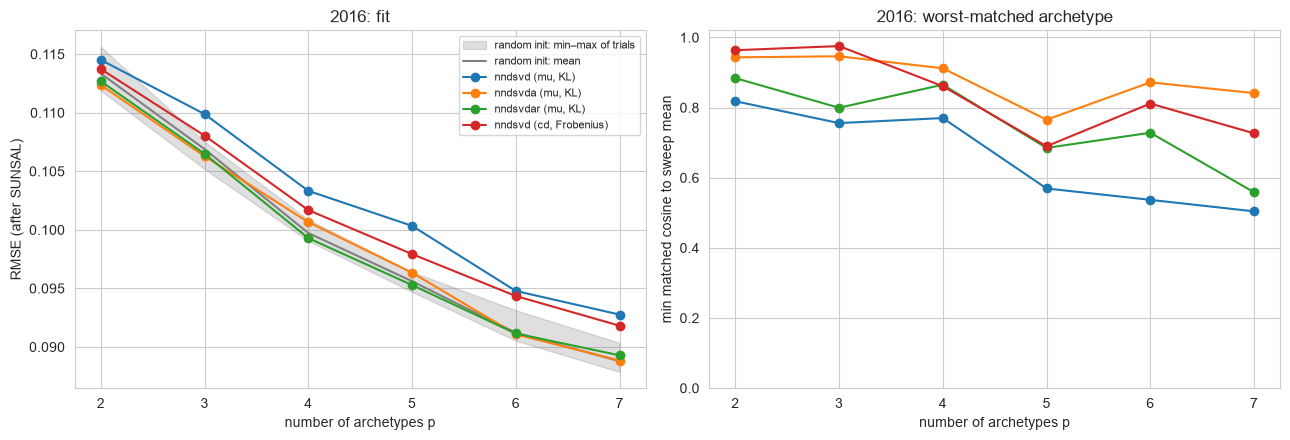

In [ ]:
ps = sorted(sweep)
trials = np.array([sweep[p]["meta"]["rmse_trials"] for p in ps])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.fill_between(ps, trials.min(axis=1), trials.max(axis=1), color="grey", alpha=0.25,
                label="random init: min–max of trials")
ax.plot(ps, trials.mean(axis=1), color="grey", lw=1.5, label="random init: mean")
for name, g in alt.groupby("variant", sort=False):
    ax.plot(g["p"], g["rmse"], marker="o", label=name)
ax.set(xlabel="number of archetypes p", ylabel="RMSE (after SUNSAL)", title=f"{YEAR}: fit")
ax.legend(fontsize=8)

ax = axes[1]
for name, g in alt.groupby("variant", sort=False):
    ax.plot(g["p"], g["cos_min"], marker="o", label=name)
ax.set(xlabel="number of archetypes p", ylabel="min matched cosine to sweep mean",
       title=f"{YEAR}: worst-matched archetype", ylim=(0, 1.02))
plt.tight_layout()

## Takeaways

Numbers below are from the run of 2026-10-20 (section 3: 2016 only); rerun the cells
above after regenerating the data.

- **The zeros really are frozen.** Under `mu`, 100% of the NNDSVD init's zeros are still
  exactly 0 after fitting (2016, p = 4: 32.5% of W, 40.4% of H). With `cd`, only 23% (W)
  and 7% (H) of them stay 0.
- **Baked NNDSVD (`mu`, KL) fits worse.** In every year and p its RMSE is above the
  random-init mean (+1.0% to +7.1%, growing with p), and it beats at most 2 of the 50
  trials (none in 27 of 30 runs). 18–45% of its loadings are pinned at 0.
- **The patterns mostly survive.** Its archetypes match the random-init consensus with
  median cosine 0.87 (53 of 135 ≥ 0.9). The worst-matched archetype drifts at larger p
  (down to 0.37), so the disagreement is concentrated in a few minor archetypes.
- **Filling the zeros removes the fit penalty (2016).** `nndsvda` and `nndsvdar` land
  within ±1% of the random-init mean, inside the trials' range. `nndsvda` also agrees
  best with the consensus: worst archetype cosine 0.77–0.95, against 0.50–0.82 for
  `nndsvd`. `nndsvd` with `cd`/Frobenius sits in between (+0.3% to +3.4%), but it also
  changes the loss.
- **For the paper:** the worse fit of NNDSVD + `mu` comes from the solver freezing the
  init's zeros. It is not evidence that a deterministic init finds different voting
  patterns. A like-for-like deterministic reference for the KL/`mu` sweep is `nndsvda`
  (`run_nndsvd.py --init nndsvda`). If plain `nndsvd` is reported, state this limitation.